In [1]:
#Mount your drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Code
1.   Implement (from scratch, no specialized library) and apply PCA and LDA to MNIST to find 2 dimensional spaces.
2.   Visualize them by plotting the samples and coloring each point by label for both algorithms.

In [2]:
import six.moves.cPickle as pickle
import gzip
import os
import urllib.request

def load_data(dataset):
    ''' Loads the dataset

    :type dataset: string
    :param dataset: the path to the dataset (here MNIST)

    copied from http://deeplearning.net/ and revised by hchoi
    '''

    # Download the MNIST dataset if it is not present
    if not os.path.isfile(dataset):
        origin = (
            'http://www.iro.umontreal.ca/~lisa/deep/data/mnist/mnist.pkl.gz'
        )
        print('Downloading data from %s' % origin)
        urllib.request.urlretrieve(origin, dataset)

    print('Loading data...')

    # Load the dataset
    with gzip.open(dataset, 'rb') as f:
        try:
            train_set, valid_set, test_set = pickle.load(f, encoding='latin1')
        except:
            train_set, valid_set, test_set = pickle.load(f)
    # train_set, valid_set, test_set format: tuple(input, target)
    # input is a numpy.ndarray of 2 dimensions (a matrix)
    # where each row corresponds to an example. target is a
    # numpy.ndarray of 1 dimension (vector) that has the same length as
    # the number of rows in the input. It should give the target
    # to the example with the same index in the input.
    print('... data has been loaded!')
    return train_set, valid_set, test_set

In [3]:
train_set, val_set, test_set = load_data('mnist.pkl.gz')

train_x, train_y = train_set
val_x, val_y = val_set
test_x, test_y = test_set

Loading data...
... data has been loaded!


In [13]:
#PCA
import numpy as np

mean = np.mean(train_x, axis=0)
norm = train_x - mean
n= norm.shape[0]

cov = np.cov(norm.T)
cov = (norm.T@norm)/(n - 1)

eigval, eigvec = np.linalg.eig(cov)
eigval_dim2 = np.argsort(eigval)[::-1]
eigvec_dim2 = eigvec[:, eigval_dim2[:2]]

dim2_pda = norm @ eigvec_dim2

In [9]:
#LDA
# within class cov
classes = np.unique(train_y)
class_means = []
n_list = []

D = train_x.shape[1]
S_W = np.zeros((D, D))

for c in classes:
    x_c = train_x[train_y == c]
    mean_c = np.mean(x_c, axis=0)
    norm_c = x_c - mean_c.reshape(1, -1)
    cov_c = norm_c.T @ norm_c
    S_W += cov_c

# between class
S_B = np.zeros((D, D))

for c in classes:
    x_c = train_x[train_y == c]
    mean_c = np.mean(x_c, axis=0)
    norm_mu = (mean_c-mean).reshape(D,1)
    n_c = x_c.shape[0]
    cov = n_c*(norm_mu @ norm_mu.T)
    S_B += cov

# total
lda = np.linalg.pinv(S_W) @ S_B

eigvals, eigvecs = np.linalg.eig(lda)
idx = np.argsort(eigvals)[::-1]
W = eigvecs[:, idx[:2]]
dim2_lda = train_x @ W


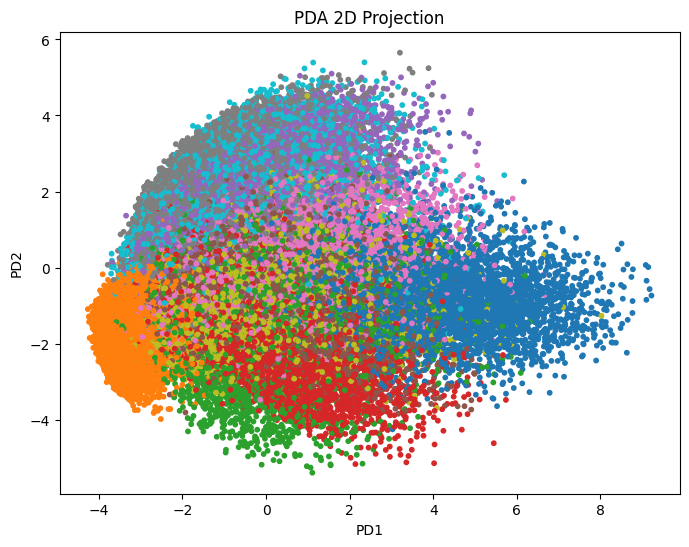

In [14]:
import matplotlib.pyplot as plt

#PCA visualization
plt.figure(figsize=(8,6))
plt.scatter(dim2_pda[:,0], dim2_pda[:,1], c=train_y, cmap='tab10', s=10)
plt.title("PDA 2D Projection")
plt.xlabel("PD1")
plt.ylabel("PD2")
plt.show()

/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.12/dist-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


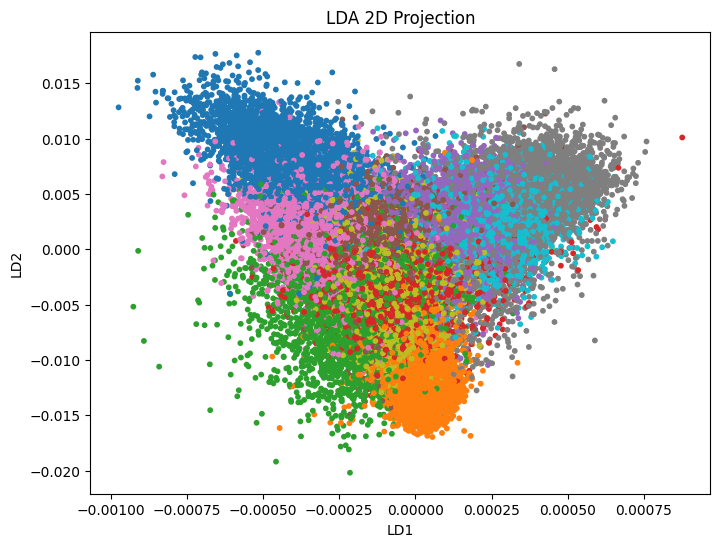

In [10]:
#LDA visualization

plt.figure(figsize=(8,6))
plt.scatter(dim2_lda[:,0], dim2_lda[:,1], c=train_y, cmap='tab10', s=10)
plt.title("LDA 2D Projection")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.show()

##Report


1.   In general terms, what is the goal of dimensionality reduction? What kind of information can it provide us?
2.   Compare PCA and LDA algorithms in terms of: mathematical computation, type of algorithm (supervised or unsupervised), efficiency, etc. What are the pros and cons of each algorithm? (ex. PCA = variance preservation, unsupervised; LDA = class separability, supervised, etc.)
3.   Observe the two resulting clustered images. Which method made the 'better' separation of the data w.r.t. the labels? (you can provide a quantifiable metric for separability if you want.)
4.  In practice, high-dimensional datasets are common. How can dimensionality reduction help subsequent algorithms?
5.   Conclude with some thoughts and things you learned from this homework.

1. In data analysis, human intuition plays an important role, but as the number of dimensions increases, it becomes difficult for people to interpret data intuitively. Therefore, dimensionality reduction is performed to make it easier to understand the meaning of the data. For example, the MNIST dataset we are working with consists of 784-dimensional data, which cannot be directly understood by the human eye. By reducing it to two dimensions and visualizing the data distribution on a plane, we can intuitively observe which data points are related to each other. In addition, dimensionality reduction is also related to avoiding the so-called curse of dimensionality often mentioned in machine learning. As dimensionality increases, the volume of the space grows too quickly, causing the available data to become sparse. As a result, the amount of data required to obtain reliable results often increases exponentially with the number of dimensions. In high-dimensional spaces, all objects become sparse and dissimilar in many ways, making common data organization strategies less effective. Therefore, through dimensionality reduction, we can more easily identify the relationships between data points — that is, information about their similarity.

2. Since PCA is an unsupervised learning method, it calculates the mean of the entire dataset and subtracts that same mean from all data points to compute the covariance.On the other hand, LDA is a supervised learning method, so it already knows which label each data point belongs to. It calculates the mean for each label and subtracts that label's mean from the data points belonging to that label. Then, using these class means, LDA computes the within-class scatter and the between-class scatter by using the difference between each class mean and the overall mean. When this process is implemented, it can be seen that PCA requires much less computation and time compared to LDA. The advantage of PCA is that it is simple to implement and has a fast computation speed. In addition, unlike LDA, PCA has relatively less information loss during projection. However, since PCA does not use label information, the result visualization often shows a somewhat mixed distribution where classes are not clearly separated. In contrast, LDA can express the relationships between classes more clearly than PCA, allowing for more intuitive data analysis. This is because LDA uses the label information of each data point, which provides richer information to represent relationships between data points. However, the disadvantages of LDA are that it is more complex to implement than PCA and that it causes relatively greater information loss during projection.

3. From my observation, LDA seems to separate the data more clearly than PCA. Although some parts of the dataset still appear blurred, similar to PCA, the boundaries between labels are generally more distinct in the case of LDA. This can also be explained by the formulas used when implementing PCA and LDA. While PCA finds the direction that maximizes the overall variance of the data, LDA aims to maximize the variance between classes while minimizing the variance within each class. Therefore, it is reasonable that LDA produces results with more clearly separated class boundaries.

4. When the dimensionality is reduced, the number of variables that need to be computed decreases compared to the high-dimensional case. As a result, the overall computational load becomes smaller, and both training and prediction processes run faster. In addition, by removing unnecessary or redundant information, the model becomes less affected by irrelevant features, which helps prevent overfitting. When overfitting is reduced, the model does not rely too heavily on the training data and can perform more reliably on new, unseen data. Consequently, dimensionality reduction improves the generalization ability of the model.

5. While working on the assignment, I initially found it difficult to fully understand the lecture content.
To overcome this, I referred to the textbook and carefully followed the derivation of each formula step by step. Through this process, I was able to understand not just the final results shown in the lecture, but also the reasoning behind each step and the meaning of the formulas. In particular, by deriving the equations for PCA and LDA on my own, I could clearly see how the two algorithms differ in the way they process data. After understanding the mathematical derivations, it became much easier to implement the algorithms in code. However, since I was not yet completely familiar with the built-in functions in NumPy, I often had to look up the official documentation or ask questions using generative AI tools.
Although this process was sometimes challenging, it helped me strengthen my problem-solving skills and gain a deeper understanding of how the algorithms actually work. As a result, studying the textbook and implementing the formulas myself gave me much more than just coding practice. It allowed me to understand the internal mechanisms of the algorithms more clearly, and I was able to distinguish the differences between PCA and LDA both theoretically and practically. Overall, this experience not only helped me complete the assignment but also gave me greater confidence in connecting theoretical concepts with practical implementation in future studies.

** I used GenAI to unnatural parts of my English.

** I asked the follosing questions to GenAI.

1. Then, for each of the 784 features, do we calculate the covariance, find the corresponding eigenvalues and eigenvectors, and then take the two eigenvectors with the largest eigenvalues?

2. But why do we divide by (n-1) here instead of just n?

3. Why do I use reshape()?



